# Testing confidence intervals
Author: Aleksander Filip Żarnecki (University of Warsaw)

### (0) Import libraries 

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import norm

### (1) Definition of probability intervals for assumed probability density function

Assuming gaussian probability distribution with fixed sigma

In [2]:
# Assume constant pdf width, independent on mean

def sigma(mean):
#    sig = 1
    sig = 0.5+0.5*np.log(1+mean)     # Try it for a more complicated case
    return sig

# Return value of x corresponsing to upper (one-side) limit on given CL
# Use 1-CL for lower limit

def problim(mean,cl):
    
# Use inverse survival function from scipy (inverse of 1 - cumulative distribution)

    xlim = norm.isf(1-cl)

    return mean+xlim*sigma(mean) 


### (2) Define set of hypothesis

In [3]:
# Considered values of true mean

vmean = np.linspace(0.,5.99,600)

CL = 0.95            # One sided! So the inteval will be 90% CL

# Upper an lower edges of x probability intervals

vhig = problim(vmean,CL)
vlow = problim(vmean,1-CL)


### (3)  Print interval information

In [4]:
print("\nProbability intervals for x:")

print("\n  true value    x_low     x_high")

for im in range(vmean.size) :
    print ("{:10.3f}   {:8.3f}  {:8.3f}".format(vmean[im],vlow[im],vhig[im]))



Probability intervals for x:

  true value    x_low     x_high
     0.000     -0.822     0.822
     0.010     -0.821     0.841
     0.020     -0.819     0.859
     0.030     -0.817     0.877
     0.040     -0.815     0.895
     0.050     -0.813     0.913
     0.060     -0.810     0.930
     0.070     -0.808     0.948
     0.080     -0.806     0.966
     0.090     -0.803     0.983
     0.100     -0.801     1.001
     0.110     -0.798     1.018
     0.120     -0.796     1.036
     0.130     -0.793     1.053
     0.140     -0.790     1.070
     0.150     -0.787     1.087
     0.160     -0.784     1.104
     0.170     -0.782     1.122
     0.180     -0.779     1.139
     0.190     -0.775     1.155
     0.200     -0.772     1.172
     0.210     -0.769     1.189
     0.220     -0.766     1.206
     0.230     -0.763     1.223
     0.240     -0.759     1.239
     0.250     -0.756     1.256
     0.260     -0.752     1.272
     0.270     -0.749     1.289
     0.280     -0.745     1.305
     0.2

### (4) Draw probability intervals

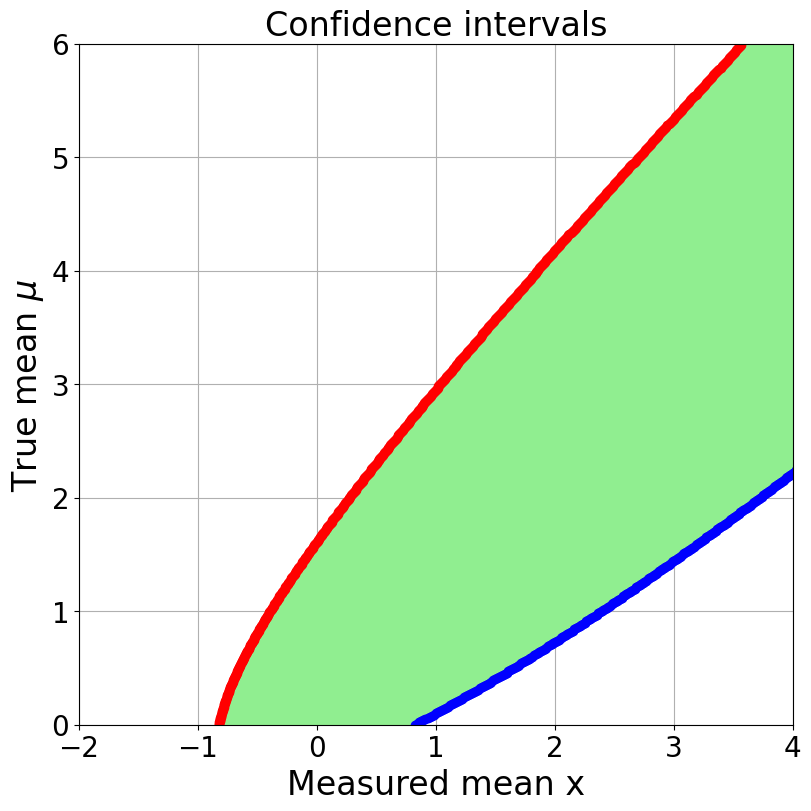

In [5]:
# Plot ranges

Xmin=-2
Xmax=4
Ymin=0
Ymax=6


plt.figure(figsize=(8, 8),layout='constrained')

plt.hlines(vmean,vlow,vhig,color='lightgreen',linewidth=5)

plt.plot(vlow,vmean,'o',color='red')
plt.plot(vhig,vmean,'o',color='blue')

plt.title("Confidence intervals",size=24)
plt.xlabel("Measured mean x",size=24)
plt.ylabel("True mean $\\mu$",size=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlim([Xmin,Xmax])
plt.ylim([Ymin,Ymax])
plt.grid(which='major', axis='both')


fname = '06_gauss_interval_1_'+str(vmean.size)+'_mod.png'
plt.savefig(fname)


### (5) Hypothetical measurement

In [6]:
Xm = 2.3

# Look for limit point in the probability interval tables

iuh = np.argmax(Xm < vhig)
iul = np.argmax(Xm < vlow)

# Interpolate between points for higher precision (linear interpolation)

frac = (Xm-vlow[iul-1])/(vlow[iul]-vlow[iul-1])
ul=frac*vmean[iul]+(1-frac)*vmean[iul-1]
print(f'Upper limit : {ul:.4f}')

frac = (Xm-vhig[iuh-1])/(vhig[iuh]-vhig[iuh-1])
ll = frac*vmean[iuh]+(1-frac)*vmean[iuh-1]
print(f'Lower limit : {ll:.4f}')

Upper limit : 4.5287
Lower limit : 0.9348


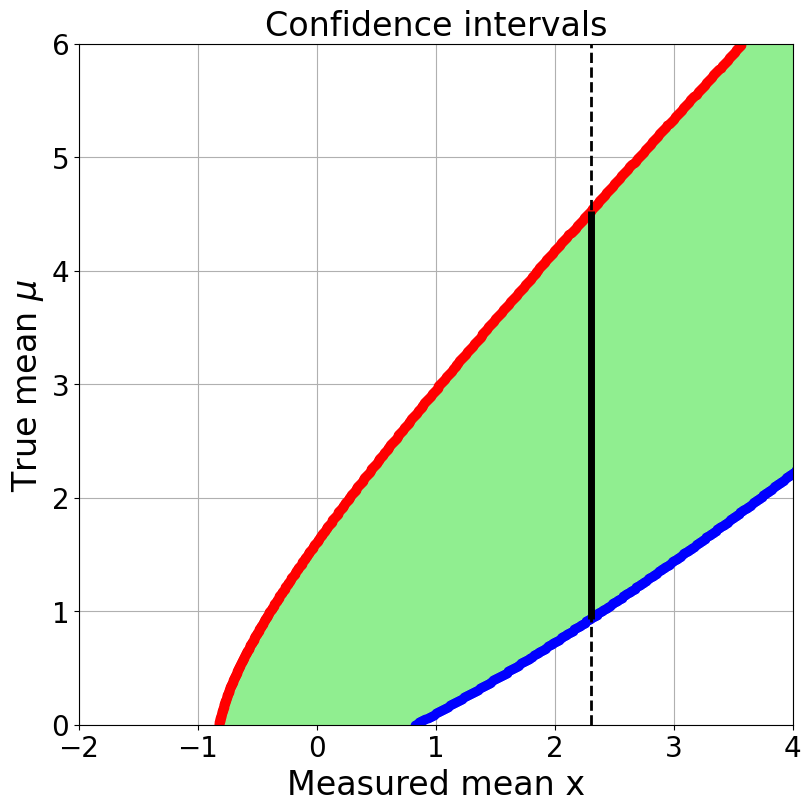

In [7]:
plt.figure(figsize=(8, 8),layout='constrained')

plt.hlines(vmean,vlow,vhig,color='lightgreen',linewidth=5)

plt.plot(vlow,vmean,'o',color='red')
plt.plot(vhig,vmean,'o',color='blue')

plt.vlines(Xm,Ymin,Ymax,color='black',linewidth=2,linestyles='dashed')
plt.vlines(Xm,ll,ul,color='black',linewidth=5,linestyles='solid')

plt.title("Confidence intervals",size=24)
plt.xlabel("Measured mean x",size=24)
plt.ylabel("True mean $\\mu$",size=24)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlim([Xmin,Xmax])
plt.ylim([Ymin,Ymax])
plt.grid(which='major', axis='both')


fname = '06_gauss_interval_2_'+str(vmean.size)+'_mod.png'
plt.savefig(fname)
